## Classification Model Accuracy Comparison

The following bar chart compares the classification accuracy achieved by the different machine learning models used in the experiment. Accuracy is used as the evaluation metric to determine the proportion of correctly classified samples.

The model with the highest bar represents the best-performing model in terms of classification accuracy. This visualization makes it easy to compare the performance of all models and identify the most accurate classifier.

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

## Loading and Inspecting the Dataset

In this step, the Spotify Genre Prediction dataset is loaded into a Pandas DataFrame using the `read_csv()` function. The `display.max_columns` option is set to `None` so that all columns are displayed when inspecting the dataset.

The `head()` function is then used to display the first five rows of the dataset. This initial inspection helps understand the structure of the data, identify the available features, and verify that the dataset has been loaded correctly.

In [3]:
import pandas as pd

In [4]:
pd.set_option('display.max_columns', None)
df=pd.read_csv(r'C:\Users\bhavy\OneDrive\Spotify_Genre_Prediction\dataset\dataset.csv')
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## Dataset Information

The `df.info()` function is used to obtain a concise summary of the dataset. It displays the total number of rows and columns, column names, the number of non-null values, and the data type of each feature.

This step helps identify missing values, understand the structure of the dataset, and determine which columns may require preprocessing or data type conversion before applying machine learning models.

In [2]:
df.info()

NameError: name 'df' is not defined

## Unique Track Genres

The `unique()` function is used to identify all the distinct genres present in the `track_genre` column. This step helps understand the number and types of target classes available in the dataset.

Since `track_genre` represents the genre to be predicted, examining its unique values is important before model training. It also helps verify the class labels and understand the multi-class classification problem.

In [7]:
df['track_genre'].unique()

<StringArray>
[   'acoustic',    'afrobeat',    'alt-rock', 'alternative',     'ambient',
       'anime', 'black-metal',   'bluegrass',       'blues',      'brazil',
 ...
     'spanish',       'study',     'swedish',   'synth-pop',       'tango',
      'techno',      'trance',    'trip-hop',     'turkish', 'world-music']
Length: 114, dtype: str

## Distribution of Track Genres

The `value_counts()` function is used to calculate the number of tracks belonging to each genre in the `track_genre` column. This provides an overview of the distribution of the target classes in the dataset.

Analyzing the genre distribution helps determine whether the dataset is balanced or contains significant differences in the number of samples across genres. This information is important for selecting appropriate preprocessing and classification techniques.

In [8]:
genre_counts = df["track_genre"].value_counts()

print(genre_counts)

track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
               ... 
techno         1000
trance         1000
trip-hop       1000
turkish        1000
world-music    1000
Name: count, Length: 114, dtype: int64


## Minimum Number of Samples per Genre

The `min()` function is used to determine the minimum number of samples available in any genre. This helps assess whether all genre classes have a sufficient number of samples for training and evaluation.

A balanced number of samples across genres can help the classification models learn each class effectively and reduce the possibility of bias toward classes with more samples.

In [10]:
print("Minimum samples in a genre:", genre_counts.min())

Minimum samples in a genre: 1000


## Filtering Genres with Sufficient Samples

In this step, genres with fewer than 50 samples are removed from the dataset. A minimum sample threshold of 50 is selected to ensure that each remaining genre has enough data for effective model training and evaluation.

The valid genres are identified using the `value_counts()` results, and a filtered dataset is created containing only those genres that meet the minimum sample requirement.

The number of samples before and after filtering, along with the total number of remaining genres, is then displayed. This helps verify the effect of the filtering process and ensures that the dataset contains sufficient samples for each classification class.

In [11]:
min_samples = 50

valid_genres = genre_counts[genre_counts >= min_samples].index

df_filtered = df[df["track_genre"].isin(valid_genres)].copy()

print("Original samples:", len(df))
print("After filtering:", len(df_filtered))
print("Number of genres:", df_filtered["track_genre"].nunique())

Original samples: 114000
After filtering: 114000
Number of genres: 114


## Removing Unnecessary Columns

In this step, columns that are not required for genre classification are removed from the dataset. These columns mainly contain identifiers or descriptive information that does not contribute directly to the prediction task.

The following columns are removed:

- `Unnamed: 0` – unnecessary index column
- `track_id` – unique track identifier
- `artists` – artist information
- `album_name` – album name
- `track_name` – track title

The `errors="ignore"` parameter ensures that the code continues to execute even if any of these columns are not present in the dataset.

Finally, the shape of the dataset is displayed to verify the number of rows and columns remaining after the removal process.

In [13]:
# Drop unnecessary columns
columns_to_drop = [
    "Unnamed: 0",
    "track_id",
    "artists",
    "album_name",
    "track_name"
]

df = df.drop(columns=columns_to_drop, errors="ignore")

print("Dataset shape after dropping columns:", df.shape)

Dataset shape after dropping columns: (114000, 16)


In [14]:
df.head()

,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## Checking Dataset Columns

In this step, the column names present in the dataset are displayed using the `df.columns` attribute. The total number of columns is then calculated using the `len()` function.

This step helps verify the current structure of the dataset after removing unnecessary columns and confirms which features are available for further preprocessing and model development.

In [15]:
print(df.columns)
print("Number of columns:", len(df.columns))

Index(['popularity', 'duration_ms', 'explicit', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'track_genre'],
      dtype='str')
Number of columns: 16


## Checking for Missing Values

The `isnull().sum()` function is used to identify the number of missing or null values present in each column of the dataset.

Checking for missing values is an important preprocessing step because missing data can affect the performance and accuracy of machine learning models. If missing values are identified, appropriate techniques such as removing affected records or filling the missing values can be applied.

The output shows the total number of missing values for each feature.

In [16]:
df.isnull().sum()

popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

## Converting the Explicit Feature to Integer

In this step, the `explicit` column is converted from its existing data type into an integer data type using the `astype(int)` function.

The `explicit` feature typically represents whether a track contains explicit content, with values such as `True` and `False`. Converting these Boolean values into integers changes them to `1` and `0`, respectively.

This conversion makes the feature suitable for machine learning algorithms that require numerical input.

In [17]:
df["explicit"] = df["explicit"].astype(int)

## Encoding the Target Variable

In this step, the `LabelEncoder` is used to convert the categorical `track_genre` labels into numerical values. Machine learning classification algorithms require the target variable to be represented in a numerical format.

Each unique music genre is assigned a unique integer label. The encoded values are stored in a new column named `genre_encoded`, while the original `track_genre` column is preserved.

This encoded target variable will be used during the model training and evaluation stages.

In [21]:
label_encoder = LabelEncoder()
df["genre_encoded"] = label_encoder.fit_transform(df["track_genre"])

## Feature Scaling

In this step, `StandardScaler` is used to standardize the input features in the training and testing datasets. Standardization transforms the features so that they have a mean of approximately 0 and a standard deviation of 1.

The scaler is fitted only on the training data using `fit_transform()`. The same fitted scaler is then applied to the test data using `transform()`. This prevents information from the test dataset from influencing the training process and avoids data leakage.

Feature scaling is particularly important for models such as Logistic Regression, K-Nearest Neighbors, Support Vector Machines, and Neural Networks, where differences in feature magnitudes can affect model performance.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [27]:
df.head()

,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,genre_encoded
0,73,230666,0,0.676,0.4610,1,6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,0
1,55,149610,0,0.420,0.1660,1,17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,0
2,57,210826,0,0.438,0.3590,0,9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,0
3,71,201933,0,0.266,0.0596,0,18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,0
4,82,198853,0,0.618,0.4430,2,9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,0


## Descriptive Statistics

The `df.describe()` function is used to generate descriptive statistics for the numerical features in the dataset. It provides important statistical information such as the count, mean, standard deviation, minimum value, 25th percentile, median (50th percentile), and maximum value.

This analysis helps understand the distribution, range, central tendency, and variability of the numerical features. It can also help identify unusual values or potential outliers that may need further preprocessing.

In [28]:
df.describe()

,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,genre_encoded
count,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,33.238535,2.280292e+05,0.085500,0.566800,0.641383,5.309140,8.260042,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035,56.500000
std,22.305078,1.072977e+05,0.279626,0.173542,0.251529,3.559987,5.027559,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621,32.907844
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.001000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,17.000000,1.740660e+05,0.000000,0.456000,0.472000,2.000000,5.003000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000,28.000000
50%,35.000000,2.129060e+05,0.000000,0.580000,0.685000,5.000000,7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000,56.500000
75%,50.000000,2.615060e+05,0.000000,0.695000,0.854000,8.000000,10.013000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000,85.000000
max,100.000000,5.237295e+06,1.000000,0.985000,1.000000,11.000000,49.531000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000,113.000000


## Distribution of Tracks Across Genres

The following bar chart visualizes the distribution of tracks across all music genres in the dataset. The number of tracks belonging to each genre is represented on the y-axis, while the different genres are displayed on the x-axis.

Sorting the genre counts before plotting makes it easier to compare the number of tracks available for each genre. This visualization helps identify whether the dataset is balanced across genres and highlights genres with relatively higher or lower numbers of tracks.

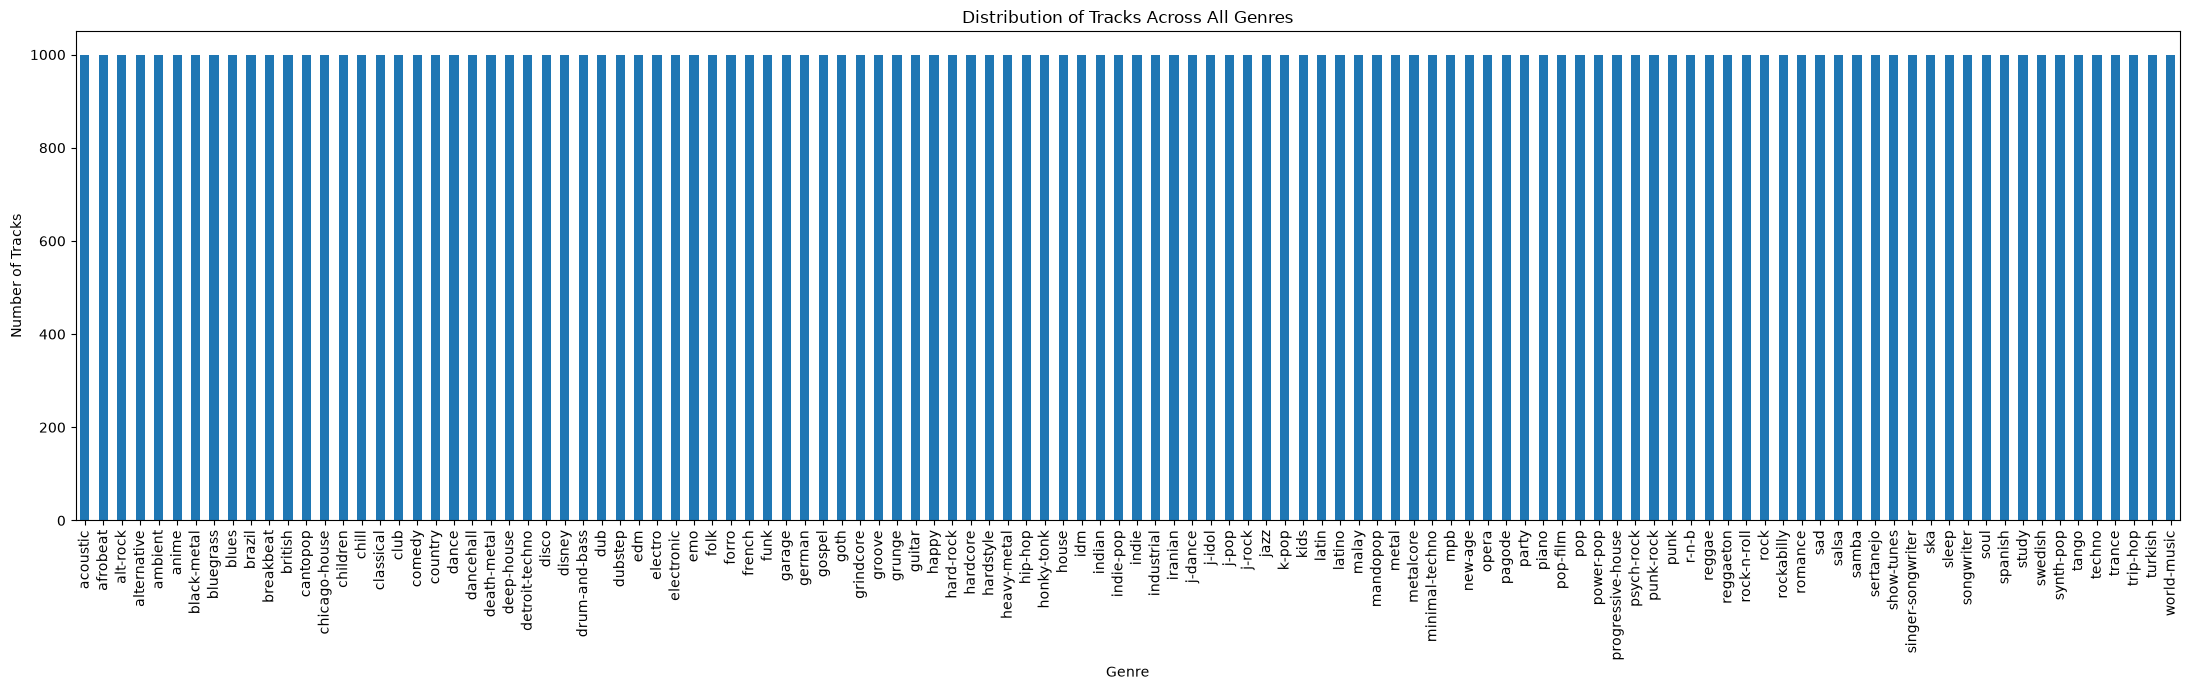

In [38]:
plt.figure(figsize=(22, 7))

genre_counts.sort_values().plot(kind="bar")

plt.title("Distribution of Tracks Across All Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

## Distribution of Track Popularity

The histogram below shows the distribution of track popularity scores in the dataset. The `popularity` feature represents the popularity level of each track, and the histogram groups these values into 30 intervals (bins).

This visualization helps understand how popularity values are distributed across the dataset. It can also reveal whether the values are concentrated in a particular range, evenly distributed, or contain potential extreme values.

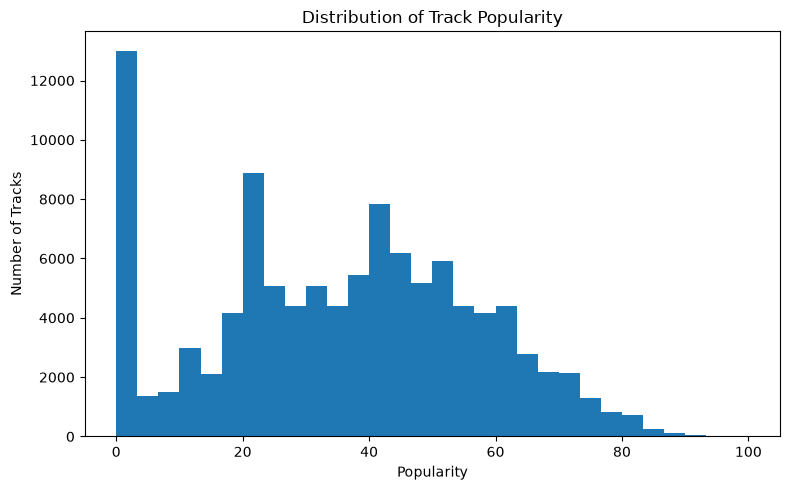

In [79]:
plt.figure(figsize=(8, 5))

plt.hist(df["popularity"], bins=30)

plt.title("Distribution of Track Popularity")
plt.xlabel("Popularity")
plt.ylabel("Number of Tracks")

plt.tight_layout()
plt.show()

## Distribution of Track Energy

The histogram below shows the distribution of the `energy` feature across all tracks in the dataset. Energy is a numerical audio feature that represents the perceptual intensity and activity of a track, with higher values generally indicating more energetic music.

The values are divided into 30 bins to visualize how energy levels are distributed across the dataset. This analysis helps identify the most common energy ranges and understand the overall characteristics of the tracks.

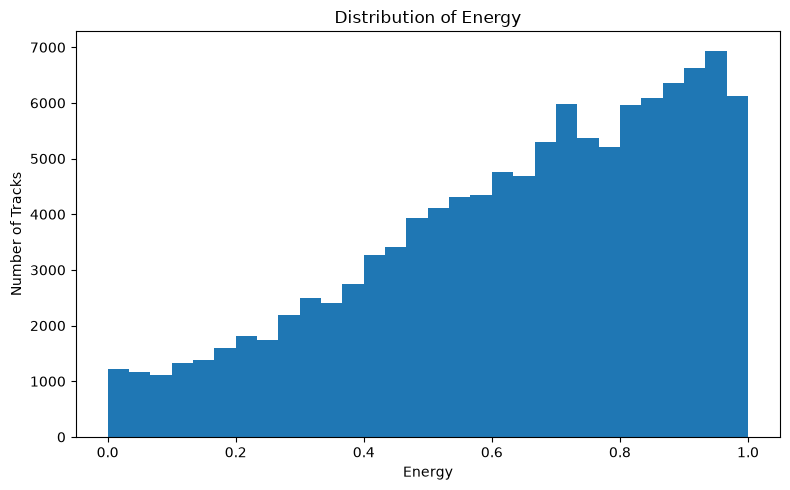

In [40]:
plt.figure(figsize=(8, 5))

plt.hist(df["energy"], bins=30)

plt.title("Distribution of Energy")
plt.xlabel("Energy")
plt.ylabel("Number of Tracks")

plt.tight_layout()
plt.show()

## Distribution of Major and Minor Tracks

The following bar chart compares the number of tracks in the dataset based on their musical mode. The `mode` feature represents the tonal modality of a track, where `0` corresponds to Minor and `1` corresponds to Major.

The `value_counts()` function is used to count the tracks belonging to each mode, and `sort_index()` arranges the values in the correct order. The visualization helps understand the distribution of major and minor tracks in the dataset.

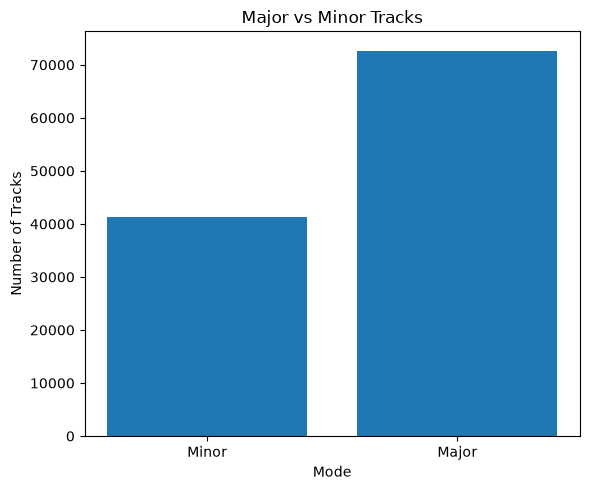

In [41]:
mode_counts = df["mode"].value_counts().sort_index()

plt.figure(figsize=(6, 5))

plt.bar(
    ["Minor", "Major"],
    mode_counts.values
)

plt.title("Major vs Minor Tracks")
plt.xlabel("Mode")
plt.ylabel("Number of Tracks")

plt.tight_layout()
plt.show()

## Correlation Matrix of Spotify Audio Features

In this step, a correlation matrix is calculated for the selected numerical audio features using the `corr()` function. Correlation measures the strength and direction of the linear relationship between two numerical variables, with values ranging from -1 to +1.

A heatmap is created using `matplotlib` to visually represent the correlation values. Positive correlations indicate that two features tend to increase together, while negative correlations indicate that one feature tends to increase as the other decreases. Values close to zero indicate a weak or negligible linear relationship.

The correlation values are displayed inside the heatmap with two decimal places. This analysis helps identify relationships between Spotify audio features and can assist in understanding feature dependencies before model training.

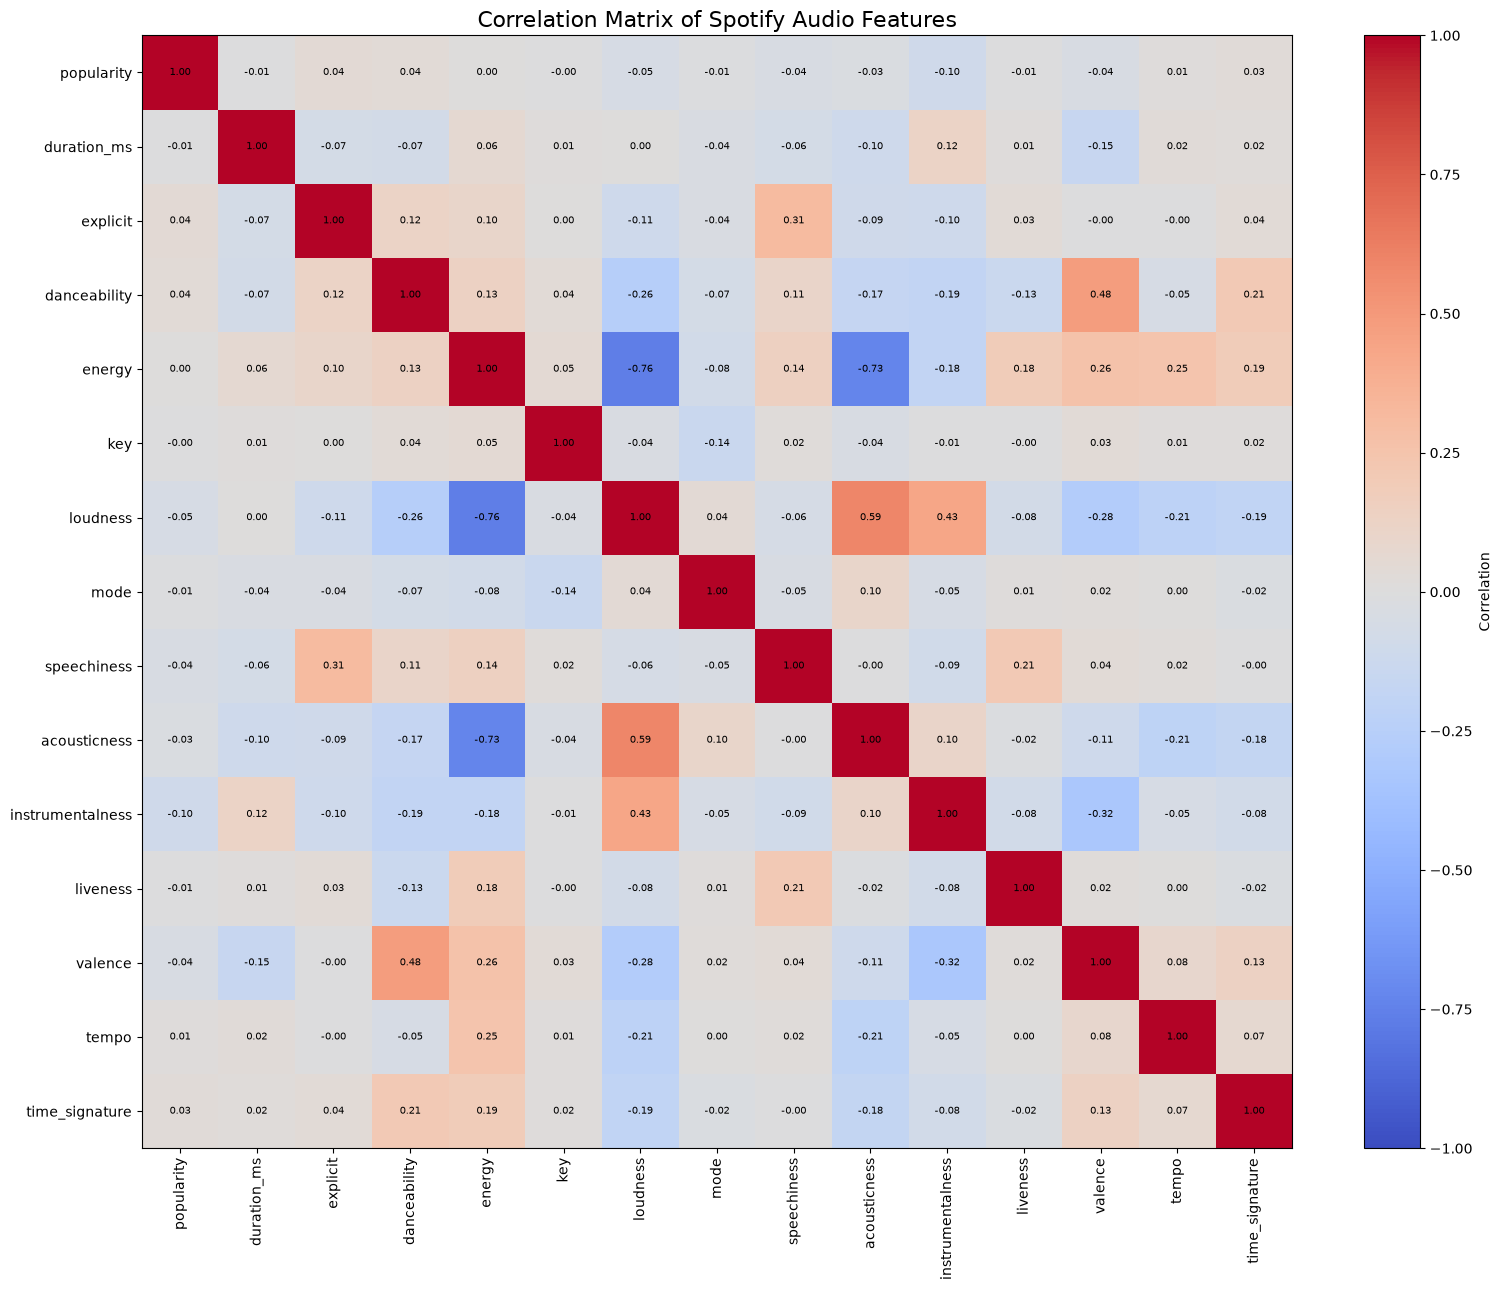

In [43]:
numeric_features = [
    "popularity",
    "duration_ms",
    "explicit",
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature"
]

# Calculate correlation
correlation = df[numeric_features].corr()

# Create figure
plt.figure(figsize=(16, 13))

# Heatmap
plt.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

# Colorbar
plt.colorbar(label="Correlation")

# Axis labels
plt.xticks(
    range(len(numeric_features)),
    numeric_features,
    rotation=90
)

plt.yticks(
    range(len(numeric_features)),
    numeric_features
)

# Display correlation values with 2 decimal places
for i in range(len(numeric_features)):
    for j in range(len(numeric_features)):
        plt.text(
            j,
            i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

plt.title("Correlation Matrix of Spotify Audio Features", fontsize=16)

plt.tight_layout()
plt.show()

## Top 20 Genres by Average Danceability

In this step, the average danceability score is calculated for each music genre using the `groupby()` and `mean()` functions. Danceability represents how suitable a track is for dancing based on its musical characteristics.

The genres are sorted in descending order according to their average danceability, and the top 20 genres are visualized using a bar chart. This analysis helps identify which music genres have the highest average danceability and provides insight into the relationship between musical genre and dance-oriented characteristics.

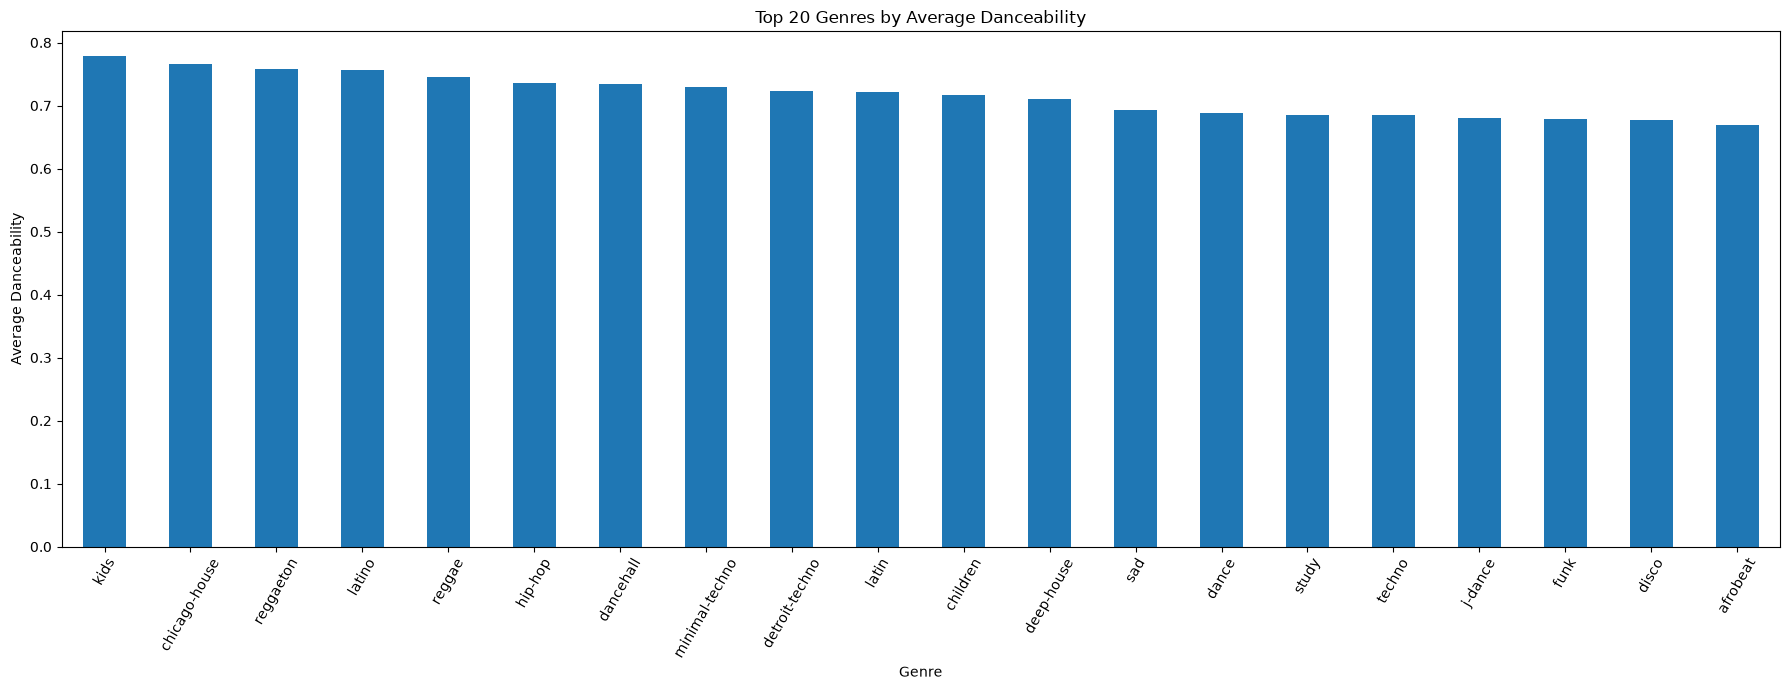

In [44]:
genre_danceability = (
    df.groupby("track_genre")["danceability"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(18, 7))

genre_danceability.head(20).plot(kind="bar")

plt.title("Top 20 Genres by Average Danceability")
plt.xlabel("Genre")
plt.ylabel("Average Danceability")
plt.xticks(rotation=60)

plt.tight_layout()
plt.show()

## Selecting Features for Boxplot Analysis

In this step, a list of important numerical audio features is selected for boxplot analysis. The selected features include popularity, danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence, and tempo.

Boxplots are useful for examining the distribution and spread of numerical features. They show the median, quartiles, overall range, and potential outliers in each feature.

This analysis helps identify unusual observations and understand the variability of the selected Spotify audio features before applying machine learning models.

In [ ]:
boxplot_features = [
    "popularity",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

## Boxplot Analysis of Spotify Audio Features

The boxplot below visualizes the distribution of the selected Spotify audio features. For each feature, the box represents the interquartile range (IQR), the central line represents the median, and the whiskers show the range of typical observations. Individual points beyond the whiskers may indicate potential outliers.

Missing values are removed using `dropna()` before plotting so that they do not affect the visualization.

This analysis helps compare the spread and variability of different audio features and identify features that contain potential outliers.


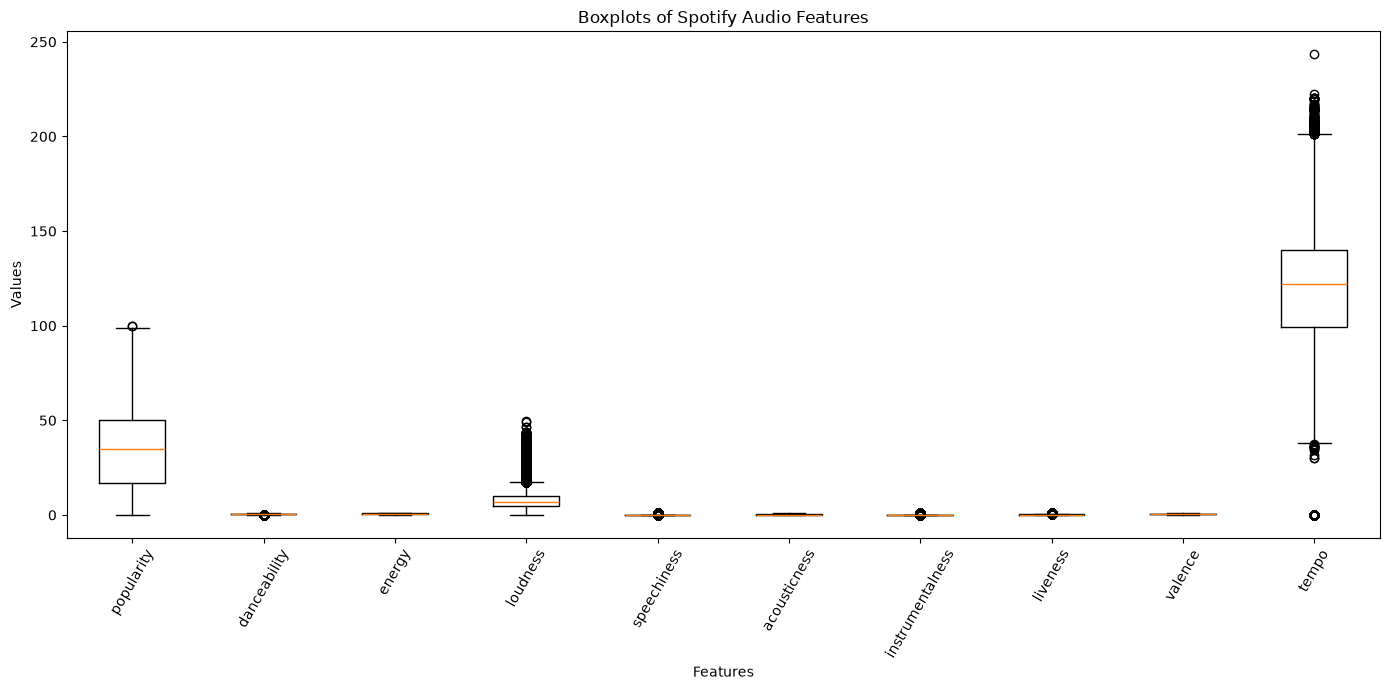

In [ ]:
plt.figure(figsize=(14, 7))

plt.boxplot(
    [df[col].dropna() for col in boxplot_features],
    tick_labels=boxplot_features
)

plt.title("Boxplots of Spotify Audio Features")
plt.xlabel("Features")
plt.ylabel("Values")
plt.xticks(rotation=60)

plt.tight_layout()
plt.show()

## Analysis of Loudness Values

In this step, descriptive statistics are calculated for the `loudness` feature using the `describe()` function. This provides information such as the count, mean, standard deviation, minimum, quartiles, and maximum values.

The 10 smallest and 10 largest loudness values are then displayed by sorting the feature in ascending and descending order. This analysis helps examine the range of loudness values and identify unusually low or high observations that may represent potential outliers.

Understanding the distribution of loudness is useful before applying machine learning models because extreme values can influence some statistical and distance-based algorithms.

In [47]:
print(df["loudness"].describe())

print("\nSmallest loudness values:")
print(df["loudness"].sort_values().head(10))

print("\nLargest loudness values:")
print(df["loudness"].sort_values(ascending=False).head(10))

count    114000.000000
mean          8.260042
std           5.027559
min           0.001000
25%           5.003000
50%           7.004000
75%          10.013000
max          49.531000
Name: loudness, dtype: float64

Smallest loudness values:
46754     0.001
29866     0.006
27206     0.006
109870    0.006
29946     0.007
10033     0.025
27074     0.025
27436     0.030
27260     0.041
27519     0.052
Name: loudness, dtype: float64

Largest loudness values:
101888    49.531
101538    49.307
101722    46.591
101360    46.251
79719     43.957
101972    43.943
101968    43.714
101476    43.504
79591     43.303
101397    43.046
Name: loudness, dtype: float64


## Outlier Detection Using the IQR Method

In this step, potential outliers are identified in the selected numerical features using the Interquartile Range (IQR) method.

For each feature, the first quartile (Q1) and third quartile (Q3) are calculated. The IQR is obtained as the difference between Q3 and Q1. The lower and upper bounds are then calculated using 1.5 times the IQR.

Values below the lower bound or above the upper bound are considered potential outliers. The number of detected outliers is calculated for each feature and displayed along with its corresponding lower and upper limits.

This analysis helps identify extreme observations that may affect model performance and determines whether additional outlier treatment is required during data preprocessing.


In [48]:
outlier_features = [
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

for col in outlier_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    print(
        f"{col:20} "
        f"Lower={lower:.3f}  "
        f"Upper={upper:.3f}  "
        f"Outliers={outliers}"
    )

popularity           Lower=-32.500  Upper=99.500  Outliers=2
duration_ms          Lower=42906.000  Upper=392666.000  Outliers=5617
danceability         Lower=0.098  Upper=1.053  Outliers=620
energy               Lower=-0.101  Upper=1.427  Outliers=0
loudness             Lower=-2.512  Upper=17.528  Outliers=6170
speechiness          Lower=-0.037  Upper=0.157  Outliers=13211
acousticness         Lower=-0.855  Upper=1.470  Outliers=0
instrumentalness     Lower=-0.074  Upper=0.123  Outliers=25246
liveness             Lower=-0.165  Upper=0.536  Outliers=8642
valence              Lower=-0.375  Upper=1.318  Outliers=0
tempo                Lower=37.940  Upper=201.349  Outliers=617


## Outlier Detection Using Z-Score

In this step, the Z-score method is used to identify potential outliers in the selected numerical features. The `zscore()` function from SciPy standardizes each feature by measuring how far an observation is from the feature's mean in terms of standard deviations.

A Z-score with an absolute value greater than 3 is considered a potential outlier. The number of such observations is calculated for each selected feature.

This method provides an additional approach for detecting extreme values and complements the previously applied IQR-based outlier analysis. Comparing both methods helps determine which features contain unusually extreme observations.

In [49]:
from scipy.stats import zscore

z_features = [
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

z_scores = df[z_features].apply(zscore)

z_outliers = (z_scores.abs() > 3).sum()

print("Z-score outliers (|Z| > 3):")
print(z_outliers)

Z-score outliers (|Z| > 3):
popularity             0
duration_ms          946
danceability         157
energy                 0
loudness            2476
speechiness         2079
acousticness           0
instrumentalness       0
liveness            3634
valence                0
tempo                201
dtype: int64


## Defining Features and Target Variable

In this step, the input features and target variable are defined for the machine learning classification task.

The `features` list contains the numerical Spotify audio characteristics that will be used as input variables for the classification models. These include popularity, duration, explicit content, danceability, energy, key, loudness, mode, speechiness, acousticness, instrumentalness, liveness, valence, tempo, and time signature.

The target variable is defined as `genre_encoded`, which contains the numerical representation of the original `track_genre` labels. The machine learning models will use the selected audio features to predict the corresponding music genre.

Separating the input features from the target variable is an essential step before splitting the dataset into training and testing sets.

In [50]:
features = [
    "popularity",
    "duration_ms",
    "explicit",
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature"
]
target = "genre_encoded"

## Checking for Duplicate Rows

In this step, the `duplicated()` function is used to identify duplicate rows in the dataset. The `sum()` function counts the total number of duplicated records.

Checking for duplicate rows is an important data preprocessing step because repeated records can introduce bias and cause certain observations to have more influence during model training.

The resulting count indicates whether duplicate records are present and whether duplicate removal is required before building the classification models.

In [51]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 7093


## Removing Duplicate Rows

In this step, duplicate rows are removed from the dataset using the `drop_duplicates()` function. Removing duplicate records ensures that the same observation is not included multiple times during model training.

After removing duplicates, `reset_index(drop=True)` is used to reset the DataFrame index so that the rows have a continuous index sequence starting from zero.

This step helps improve data quality and prevents duplicated observations from unnecessarily influencing the machine learning models.

In [53]:
df = df.drop_duplicates().reset_index(drop=True)

## Checking the Final Dataset Shape

The `df.shape` attribute is used to determine the current dimensions of the dataset after the preprocessing steps performed so far.

It returns two values:

- **Number of rows:** represents the total number of samples or tracks.
- **Number of columns:** represents the total number of features and variables available in the dataset.

This step helps verify the final dataset size before proceeding to feature selection, train-test splitting, and machine learning model development.

In [54]:
df.shape

(106907, 17)

## Defining Input Features and Target Variable

In this step, the dataset is divided into the input features (`X`) and the target variable (`y`).

The `X` variable contains the selected Spotify audio features defined earlier. These features are used by the machine learning models to learn the characteristics associated with different music genres.

The `y` variable contains the `genre_encoded` values, which represent the encoded music genres that the models are required to predict.

Therefore, `X` represents the **independent variables (input features)**, while `y` represents the **dependent variable (target/output)**.

In [57]:
X = df[features]
y = df["genre_encoded"]

## Verifying Feature and Target Dimensions

In this step, the shapes of the input feature matrix (`X`) and target variable (`y`) are checked to verify that the dataset has been prepared correctly.

The `X.shape` output shows the number of samples and input features, while `y.shape` shows the number of target labels. The list of column names is also displayed to confirm that the intended Spotify audio features are included in the input data.

Finally, `y.nunique()` determines the number of unique target classes. This represents the total number of music genres that the classification models will learn to distinguish.

These checks help ensure that the input features and target variable are correctly structured before performing the train-test split.

In [58]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

print("\nNumber of target classes:", y.nunique())

X shape: (106907, 15)
y shape: (106907,)

X columns:
['popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']

Number of target classes: 114


## Train-Test Split

In this step, the dataset is divided into training and testing subsets using the `train_test_split()` function from Scikit-learn.

A test size of 20% is used, meaning that 80% of the data is used for training the machine learning models and the remaining 20% is reserved for testing their performance.

The `random_state=42` parameter ensures that the same train-test split can be reproduced each time the code is executed. The `stratify=y` parameter maintains approximately the same distribution of music genres in both the training and testing datasets.

Finally, the number of training and testing samples is displayed to verify the split.

In [59]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 85525
Testing samples: 21382


## Feature Scaling Using StandardScaler

In this step, the input features are standardized using `StandardScaler` from Scikit-learn. Feature scaling transforms the numerical features so that they have a mean close to 0 and a standard deviation close to 1.

The scaler is fitted only on the training data using `fit_transform()`. The same fitted scaler is then applied to the testing data using `transform()`. This approach prevents information from the test set from being used during the training process and avoids data leakage.

The scaled training and testing datasets are stored in `X_train_scaled` and `X_test_scaled`, respectively. These scaled features can then be used for machine learning models that are sensitive to differences in feature magnitude.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Logistic Regression Classification Model

In this step, a Logistic Regression model is implemented as the first baseline classification model for Spotify genre prediction.

The model is trained using the standardized training features (`X_train_scaled`) and the corresponding genre labels (`y_train`). The `max_iter=2000` parameter provides sufficient iterations for the optimization process to converge, while `random_state=42` ensures reproducible results.

After training, the model predicts the genres of the test dataset. Its performance is evaluated using four metrics: **Accuracy, Macro Precision, Macro Recall, and Macro F1-Score**.

Macro averaging calculates the metric independently for each genre and then takes the average across all genres, giving equal importance to every class. The results are printed and can later be compared with other classification models.

In [62]:
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)
logistic_model.fit(X_train_scaled, y_train)
logistic_predictions = logistic_model.predict(X_test_scaled)
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision = precision_score(
    y_test,
    logistic_predictions,
    average="macro",
    zero_division=0
)

logistic_recall = recall_score(
    y_test,
    logistic_predictions,
    average="macro",
    zero_division=0
)

logistic_f1 = f1_score(
    y_test,
    logistic_predictions,
    average="macro",
    zero_division=0
)

print("Logistic Regression")
print("-------------------")
print("Accuracy :", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall   :", logistic_recall)
print("F1 Score :", logistic_f1)

Logistic Regression
-------------------
Accuracy : 0.21335702927696193
Precision: 0.17094863344443598
Recall   : 0.2057025464616823
F1 Score : 0.1760688877191725


## K-Nearest Neighbors (KNN) Classification Model

In this step, the K-Nearest Neighbors (KNN) algorithm is implemented as a baseline classification model for Spotify genre prediction.

The model is configured with `n_neighbors=5`, meaning that the five nearest training samples are considered when predicting the genre of a test sample. The `weights="distance"` parameter gives greater importance to closer neighbors, while `n_jobs=-1` allows the model to use all available CPU cores for faster computation.

The KNN model is trained using the standardized training features and then used to predict genres for the test dataset. Its performance is evaluated using **Accuracy, Macro Precision, Macro Recall, and Macro F1-Score**.

These metrics provide a comprehensive evaluation of the model's ability to classify the different music genres.

In [64]:
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    n_jobs=-1
)

knn_model.fit(X_train_scaled, y_train)

knn_predictions = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, knn_predictions)

knn_precision = precision_score(
    y_test,
    knn_predictions,
    average="macro",
    zero_division=0
)

knn_recall = recall_score(
    y_test,
    knn_predictions,
    average="macro",
    zero_division=0
)

knn_f1 = f1_score(
    y_test,
    knn_predictions,
    average="macro",
    zero_division=0
)

print("KNN")
print("---")
print("Accuracy :", knn_accuracy)
print("Precision:", knn_precision)
print("Recall   :", knn_recall)
print("F1 Score :", knn_f1)

KNN
---
Accuracy : 0.1943690955008886
Precision: 0.18930062339076206
Recall   : 0.18922861114153833
F1 Score : 0.1877869487943652


## Linear Support Vector Machine (SVM) Classification Model

In this step, a Linear Support Vector Machine (SVM) is implemented as a baseline classification model for Spotify genre prediction.

The `LinearSVC` classifier uses `C=1.0` as the regularization parameter and `max_iter=5000` to provide sufficient iterations for model convergence. The `random_state=42` parameter ensures reproducible results.

The model is trained using the standardized training features (`X_train_scaled`) and training labels (`y_train`). It then predicts the music genres for the test dataset.

The performance of the Linear SVM model is evaluated using **Accuracy, Macro Precision, Macro Recall, and Macro F1-Score**. These metrics provide an overall assessment of the model's ability to classify the multiple music genre classes.

In [66]:
svm_model = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=42
)
svm_model.fit(X_train_scaled, y_train)
svm_predictions = svm_model.predict(X_test_scaled)
svm_accuracy = accuracy_score(y_test, svm_predictions)
svm_precision = precision_score(
    y_test,
    svm_predictions,
    average="macro",
    zero_division=0
)

svm_recall = recall_score(
    y_test,
    svm_predictions,
    average="macro",
    zero_division=0
)

svm_f1 = f1_score(
    y_test,
    svm_predictions,
    average="macro",
    zero_division=0
)

print("Linear SVM")
print("----------")
print("Accuracy :", svm_accuracy)
print("Precision:", svm_precision)
print("Recall   :", svm_recall)
print("F1 Score :", svm_f1)

Linear SVM
----------
Accuracy : 0.18164811523711533
Precision: 0.11877528311888005
Recall   : 0.17409307288869594
F1 Score : 0.11384384642555269


## Random Forest Classification Model

In this step, a Random Forest classifier is implemented as a baseline machine learning model for Spotify genre prediction.

The Random Forest model consists of 300 decision trees, specified using `n_estimators=300`. The `max_depth=None` parameter allows the trees to grow until the stopping criteria are reached. `min_samples_split=2` allows a node to be split when it contains at least two samples. The `random_state=42` parameter ensures reproducible results, while `n_jobs=-1` uses all available CPU cores to improve training speed.

Unlike Logistic Regression, KNN, and Linear SVM, Random Forest is a tree-based algorithm and therefore does not require standardized input features. For this reason, the original `X_train` and `X_test` datasets are used for training and prediction.

The model performance is evaluated using **Accuracy, Macro Precision, Macro Recall, and Macro F1-Score**. These metrics are used to compare the Random Forest model with the other baseline classification models.

In [67]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_predictions)

rf_precision = precision_score(
    y_test,
    rf_predictions,
    average="macro",
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_predictions,
    average="macro",
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_predictions,
    average="macro",
    zero_division=0
)

print("Random Forest")
print("-------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)

Random Forest
-------------
Accuracy : 0.3234963988401459
Precision: 0.30384450898063275
Recall   : 0.31412175836718303
F1 Score : 0.3047942041282664


## XGBoost Classification Model

In this step, the XGBoost classifier is implemented as the final baseline classification model for Spotify genre prediction.

The model is configured with 300 boosting trees using `n_estimators=300` and a maximum tree depth of 8. The `learning_rate=0.1` controls the contribution of each tree to the final prediction. The `subsample=0.8` and `colsample_bytree=0.8` parameters introduce randomness by using 80% of the training samples and features during boosting, which can help reduce overfitting.

Since this is a multi-class classification problem, the `multi:softmax` objective is used with `num_class=114`, representing the 114 genre classes. The `mlogloss` evaluation metric is used to monitor multi-class classification performance. The `hist` tree method provides an efficient histogram-based approach for training.

The model is trained using the original training features (`X_train`) and evaluated on `X_test`. Its performance is measured using **Accuracy, Macro Precision, Macro Recall, and Macro F1-Score**.

XGBoost results can be compared with Logistic Regression, KNN, Linear SVM, and Random Forest to determine which baseline model provides the best performance for Spotify genre classification.

In [70]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=114,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_test)

xgb_accuracy = accuracy_score(y_test, xgb_predictions)

xgb_precision = precision_score(
    y_test,
    xgb_predictions,
    average="macro",
    zero_division=0
)

xgb_recall = recall_score(
    y_test,
    xgb_predictions,
    average="macro",
    zero_division=0
)

xgb_f1 = f1_score(
    y_test,
    xgb_predictions,
    average="macro",
    zero_division=0
)

print("XGBoost")
print("-------")
print("Accuracy :", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall   :", xgb_recall)
print("F1 Score :", xgb_f1)

XGBoost
-------
Accuracy : 0.3264428023571228
Precision: 0.3181280004859639
Recall   : 0.31720013235771327
F1 Score : 0.3165361857958087


## Comparison of Classification Models

In this step, the evaluation results of all five baseline classification models are combined into a single Pandas DataFrame. The models include Logistic Regression, K-Nearest Neighbors (KNN), Linear SVM, Random Forest, and XGBoost.

For each model, four evaluation metrics are recorded: **Accuracy, Precision, Recall, and Macro F1-Score**. These metrics provide a comprehensive comparison of the classification performance across the different models.

The results are then sorted in descending order based on the **Macro F1-Score**. Macro F1 is selected as the primary comparison metric because it gives equal importance to each genre class, which is particularly useful for evaluating multi-class genre classification.

The resulting table provides an overall ranking of the baseline models and helps identify the model with the strongest classification performance.

In [72]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Linear SVM",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        logistic_accuracy,
        knn_accuracy,
        svm_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],

    "Precision": [
        logistic_precision,
        knn_precision,
        svm_precision,
        rf_precision,
        xgb_precision
    ],

    "Recall": [
        logistic_recall,
        knn_recall,
        svm_recall,
        rf_recall,
        xgb_recall
    ],

    "Macro F1": [
        logistic_f1,
        knn_f1,
        svm_f1,
        rf_f1,
        xgb_f1
    ]
})

results = results.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

print(results)

                 Model  Accuracy  Precision    Recall  Macro F1
0              XGBoost  0.326443   0.318128  0.317200  0.316536
1        Random Forest  0.323496   0.303845  0.314122  0.304794
2                  KNN  0.194369   0.189301  0.189229  0.187787
3  Logistic Regression  0.213357   0.170949  0.205703  0.176069
4           Linear SVM  0.181648   0.118775  0.174093  0.113844


## Classification Model Accuracy Comparison

The bar chart below compares the accuracy scores of the five baseline classification models: Logistic Regression, KNN, Linear SVM, Random Forest, and XGBoost.

Accuracy represents the proportion of correctly classified tracks out of all tracks in the test dataset. The visualization makes it easier to compare the overall predictive performance of the models and identify which model achieves the highest accuracy.

The results are plotted using the previously created `results` DataFrame.

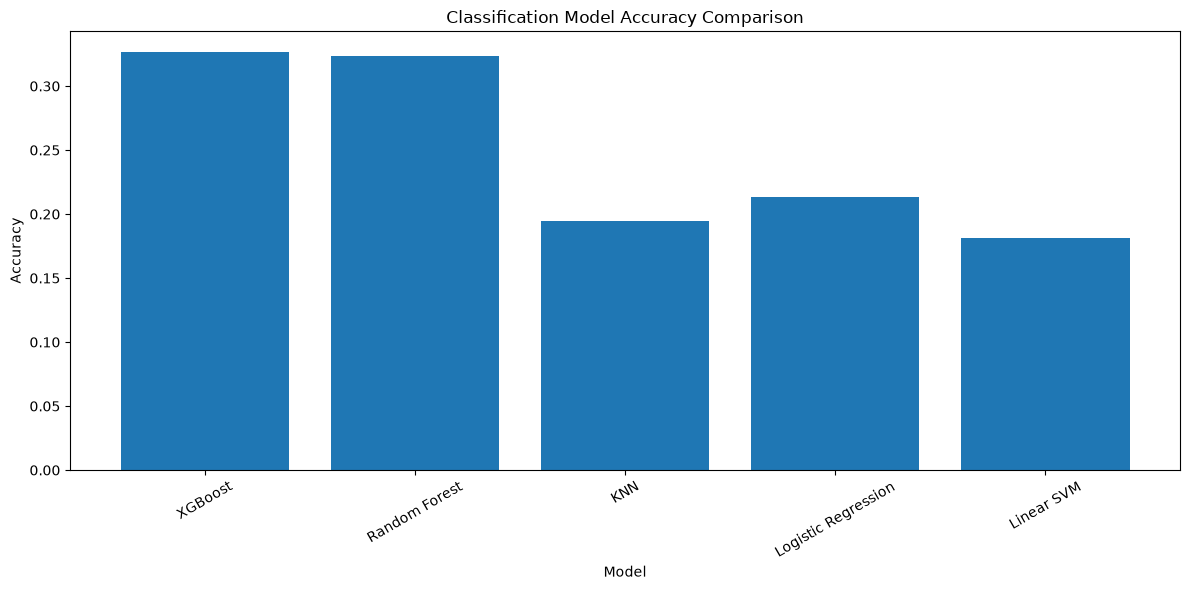

In [73]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.title("Classification Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

## Confusion Matrix Analysis

A confusion matrix is used to evaluate the performance of the classification models by comparing the actual class labels with the predicted class labels.

Since this project is a multi-class classification problem with multiple Spotify music genres, the **One-vs-Rest (OvR)** approach is used for confusion matrix analysis. In this approach, one selected genre is considered the **Positive class**, while all other genres are considered the **Negative class**.

### Components of the Confusion Matrix

The confusion matrix contains four important values:

- **True Positive (TP):** The model correctly predicts the selected genre.
- **True Negative (TN):** The model correctly predicts that a track does not belong to the selected genre.
- **False Positive (FP):** The model incorrectly predicts another genre as the selected genre.
- **False Negative (FN):** The model fails to identify the selected genre and predicts it as another genre.

### Confusion Matrix Structure

| Actual / Predicted | Negative | Positive |
|--------------------|----------|----------|
| **Negative** | TN | FP |
| **Positive** | FN | TP |

### Purpose

The confusion matrix helps to understand not only how many predictions are correct, but also the types of errors made by each model.

In this project, confusion matrices are generated separately for:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Linear Support Vector Machine (SVM)
4. Random Forest
5. XGBoost

The results are visualized using a heatmap-style plot, where **TN, FP, FN, and TP** values are displayed directly inside the matrix.

The confusion matrix provides a detailed view of model performance and helps identify whether a model is producing more false positives or false negatives for the selected Spotify genre.

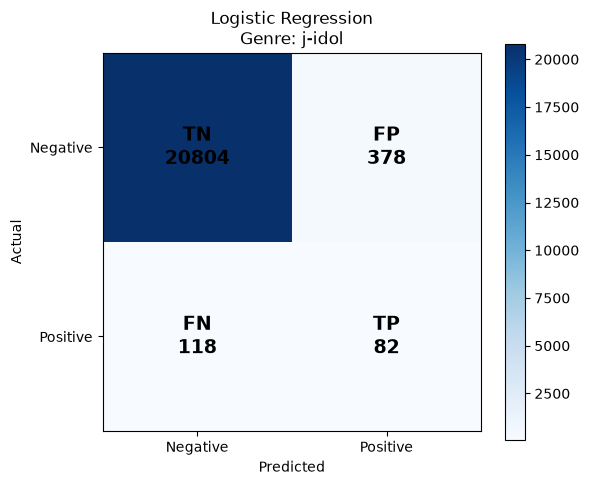

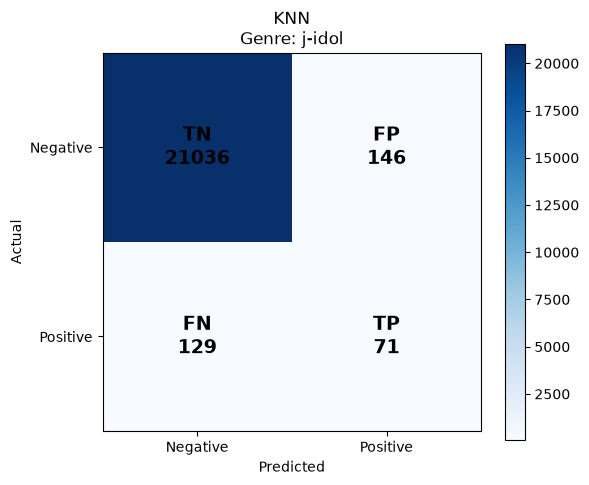

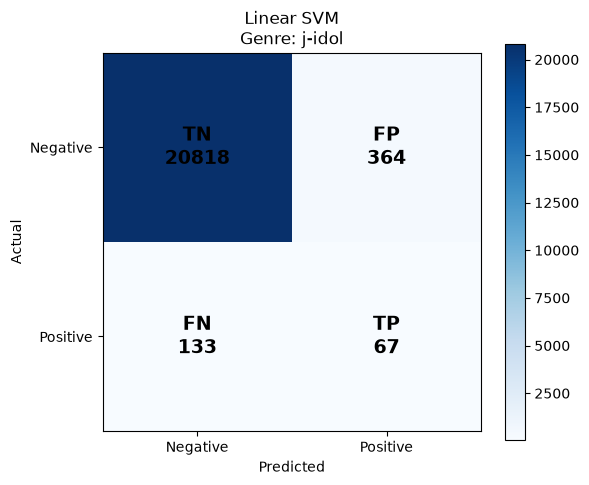

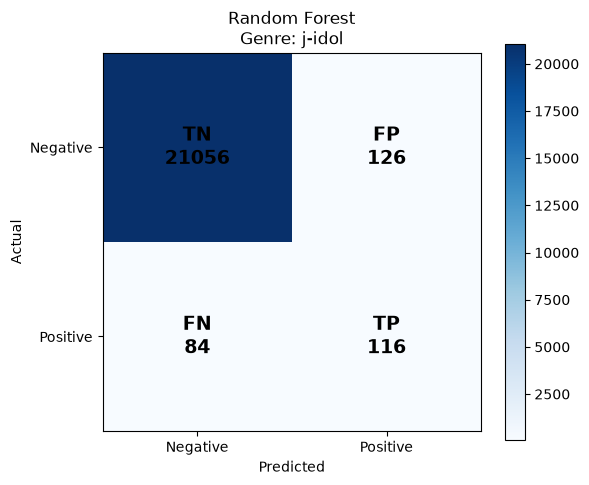

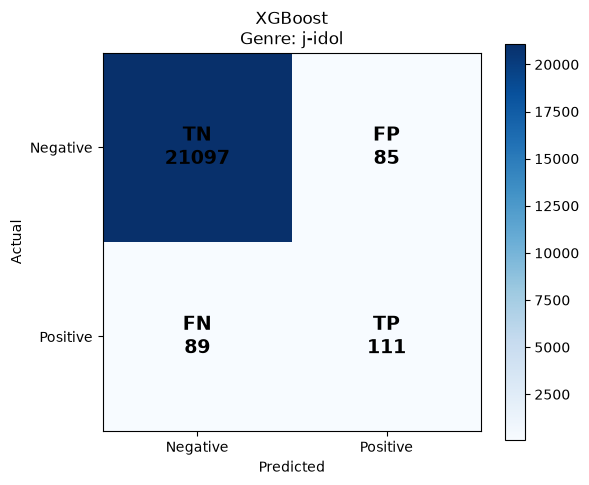

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

models = {
    "Logistic Regression": logistic_predictions,
    "KNN": knn_predictions,
    "Linear SVM": svm_predictions,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions
}

# Select most frequent genre
genre = y_test.value_counts().index[0]
genre_name = label_encoder.inverse_transform([genre])[0]

for name, pred in models.items():

    # One-vs-Rest
    actual = (y_test == genre).astype(int)
    predicted = (pred == genre).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    cm = [[tn, fp], [fn, tp]]

    plt.figure(figsize=(6, 5))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()

    plt.xticks([0, 1], ["Negative", "Positive"])
    plt.yticks([0, 1], ["Negative", "Positive"])

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{name}\nGenre: {genre_name}")

    labels = [
        [f"TN\n{tn}", f"FP\n{fp}"],
        [f"FN\n{fn}", f"TP\n{tp}"]
    ]

    for i in range(2):
        for j in range(2):
            plt.text(
                j, i, labels[i][j],
                ha="center",
                va="center",
                fontsize=14,
                fontweight="bold"
            )

    plt.tight_layout()
    plt.show()

## Best Model Selection

After training and evaluating all five machine learning models, the models are compared using Accuracy, Precision, Recall, and Macro F1-Score.

In this project, the **Macro F1-Score** is selected as the primary metric for determining the best model because the problem is a multi-class classification problem involving multiple Spotify music genres. Macro F1 gives equal importance to each genre by calculating the F1-score for every class and then taking their average.

The model with the **highest Macro F1-Score** is selected as the best-performing model.

### Selection Process

1. Obtain the evaluation results of all five models.
2. Compare their Macro F1-Scores.
3. Identify the model with the highest Macro F1-Score.
4. Display its Accuracy, Precision, Recall, and Macro F1-Score.
5. Consider this model as the best model for Spotify genre classification.

### Models Compared

- Logistic Regression
- K-Nearest Neighbors (KNN)
- Linear Support Vector Machine (SVM)
- Random Forest
- XGBoost

### Why Macro F1-Score?

Macro F1-Score is useful because it gives equal importance to every genre rather than allowing genres with more samples to dominate the overall evaluation.

Therefore, the model with the highest Macro F1-Score provides the best overall balance between **Precision and Recall across the different Spotify genres**.

In [84]:
# Find the best model based on Macro F1-Score

best_index = results["Macro F1"].idxmax()

best_model_name = results.loc[best_index, "Model"]

best_accuracy = results.loc[best_index, "Accuracy"]
best_precision = results.loc[best_index, "Precision"]
best_recall = results.loc[best_index, "Recall"]
best_f1 = results.loc[best_index, "Macro F1"]

print("=" * 50)
print("BEST MODEL")
print("=" * 50)

print("Model     :", best_model_name)
print("Accuracy  :", round(best_accuracy, 4))
print("Precision :", round(best_precision, 4))
print("Recall    :", round(best_recall, 4))
print("Macro F1  :", round(best_f1, 4))

BEST MODEL
Model     : XGBoost
Accuracy  : 0.3264
Precision : 0.3181
Recall    : 0.3172
Macro F1  : 0.3165


## Best Model Predictions

After identifying the best-performing model based on the highest Macro F1-Score, the predictions generated by that model are extracted for further analysis.

A dictionary is created to store the test-set predictions produced by all five classification models:

- Logistic Regression
- K-Nearest Neighbors (KNN)
- Linear SVM
- Random Forest
- XGBoost

The variable `best_model_name` contains the name of the model with the highest Macro F1-Score. Using this name, the corresponding prediction array is retrieved from the prediction dictionary.

These predictions represent the genre predicted by the selected best model for every sample in the test dataset.

The extracted predictions can be used for further evaluation, including:

- Classification report
- Confusion matrix
- Precision
- Recall
- F1-Score
- Actual vs predicted genre comparison

The number of predictions should be equal to the number of samples in the test dataset.

In [85]:
prediction_dictionary = {
    "Logistic Regression": logistic_predictions,
    "KNN": knn_predictions,
    "Linear SVM": svm_predictions,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions
}

best_predictions = prediction_dictionary[best_model_name]

print("Best Model:", best_model_name)
print("Number of Predictions:", len(best_predictions))

Best Model: XGBoost
Number of Predictions: 21382


## Classification Report of the Best Model

After selecting the best-performing model based on the highest Macro F1-Score, a detailed classification report is generated to evaluate its performance for each Spotify music genre.

The classification report provides four important measures:

### Precision

Precision indicates how many of the tracks predicted as a particular genre actually belong to that genre.

**Precision = TP / (TP + FP)**

### Recall

Recall indicates how many of the actual tracks belonging to a particular genre were correctly identified by the model.

**Recall = TP / (TP + FN)**

### F1-Score

F1-Score is the harmonic mean of Precision and Recall. It provides a balanced measure when both precision and recall are important.

**F1-Score = 2 × (Precision × Recall) / (Precision + Recall)**

### Support

Support represents the actual number of test samples belonging to each genre.

### Macro Average

The Macro Average calculates the metric independently for each genre and then takes the average. Every genre receives equal importance.

### Weighted Average

The Weighted Average calculates the average by considering the number of samples belonging to each genre. Genres with more samples have greater influence.

### Purpose

The classification report provides a detailed evaluation of the selected best model across all Spotify genres. It helps identify which genres are classified well and which genres are more difficult for the model to distinguish.

In [86]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

                   precision    recall  f1-score   support

         acoustic       0.26      0.28      0.27       194
         afrobeat       0.38      0.32      0.35       199
         alt-rock       0.03      0.03      0.03       176
      alternative       0.05      0.05      0.05       158
          ambient       0.34      0.35      0.34       196
            anime       0.19      0.17      0.18       200
      black-metal       0.64      0.62      0.63       199
        bluegrass       0.50      0.56      0.53       199
            blues       0.07      0.05      0.06       159
           brazil       0.11      0.13      0.12       199
        breakbeat       0.55      0.52      0.53       199
          british       0.16      0.10      0.13       194
         cantopop       0.35      0.33      0.34       200
    chicago-house       0.56      0.57      0.57       199
         children       0.51      0.47      0.49       195
            chill       0.14      0.15      0.15       

## Confusion Matrix of the Best Model

After identifying the best-performing model based on the Macro F1-Score, a multi-class confusion matrix is generated to analyze its classification performance across all Spotify music genres.

A confusion matrix compares the **actual genre labels** with the **predicted genre labels** produced by the best model.

In this matrix:

- **Rows represent the Actual Genres.**
- **Columns represent the Predicted Genres.**
- **Diagonal values** represent correctly classified tracks.
- **Off-diagonal values** represent incorrectly classified tracks.

For example, if a value appears at the intersection of the actual `rock` row and predicted `rock` column, the model correctly classified those tracks as rock.

If a value appears at the intersection of the actual `rock` row and predicted `pop` column, those rock tracks were incorrectly classified as pop.

### Purpose

The multi-class confusion matrix helps identify:

1. Which genres are classified correctly.
2. Which genres are frequently confused with each other.
3. The number of correct predictions for each genre.
4. The classification errors made by the best model.

A darker or larger value on the diagonal generally indicates a larger number of correctly classified samples for that genre.

Because this project contains multiple Spotify genres, the confusion matrix provides a detailed view of the performance of the selected best model across all classes.

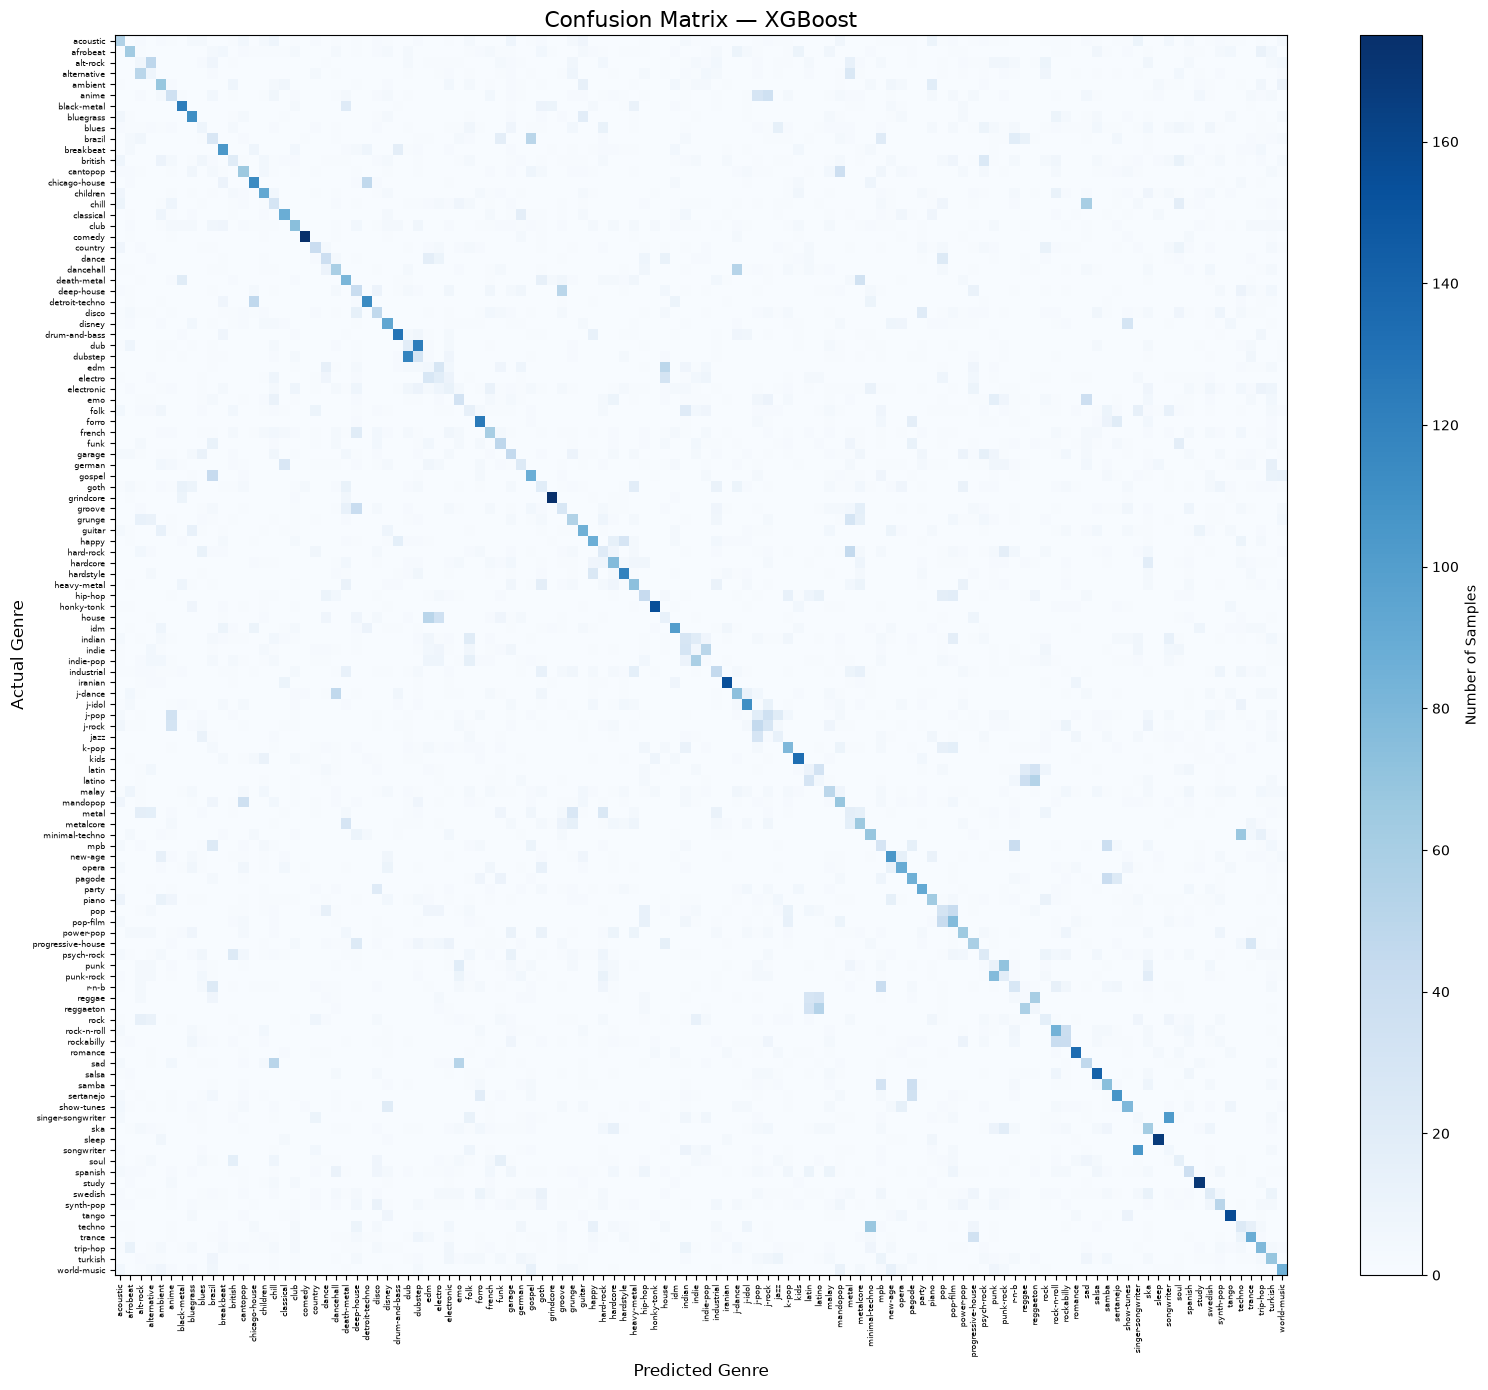

In [87]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(16, 14))

plt.imshow(
    cm,
    aspect="auto",
    cmap="Blues"
)

plt.colorbar(
    label="Number of Samples"
)

plt.title(
    f"Confusion Matrix — {best_model_name}",
    fontsize=16
)

plt.xlabel(
    "Predicted Genre",
    fontsize=12
)

plt.ylabel(
    "Actual Genre",
    fontsize=12
)

plt.xticks(
    range(len(class_labels)),
    label_encoder.inverse_transform(class_labels),
    rotation=90,
    fontsize=6
)

plt.yticks(
    range(len(class_labels)),
    label_encoder.inverse_transform(class_labels),
    fontsize=6
)

plt.tight_layout()
plt.show()

## Top 20 Genre Confusion Matrix

The complete confusion matrix contains all Spotify genres, which can make the visualization difficult to interpret because of the large number of classes.

Therefore, the 20 most frequently occurring genres in the dataset are selected for a more focused analysis.

The top 20 genres are identified using the frequency of each genre. Their corresponding encoded labels are then obtained using the previously fitted LabelEncoder.

A confusion matrix is generated for these top 20 genres using the predictions of the best-performing model.

### Purpose

The Top 20 Genre Confusion Matrix helps to:

- Analyze the classification performance of the most frequent genres.
- Identify which common genres are correctly classified.
- Identify frequently confused genre pairs.
- Provide a clearer visualization than the complete 114-class confusion matrix.
- Understand the prediction behavior of the selected best model on the major genre categories.

The rows represent the actual genres, while the columns represent the predicted genres. Values along the diagonal indicate correct classifications, while off-diagonal values indicate misclassifications.

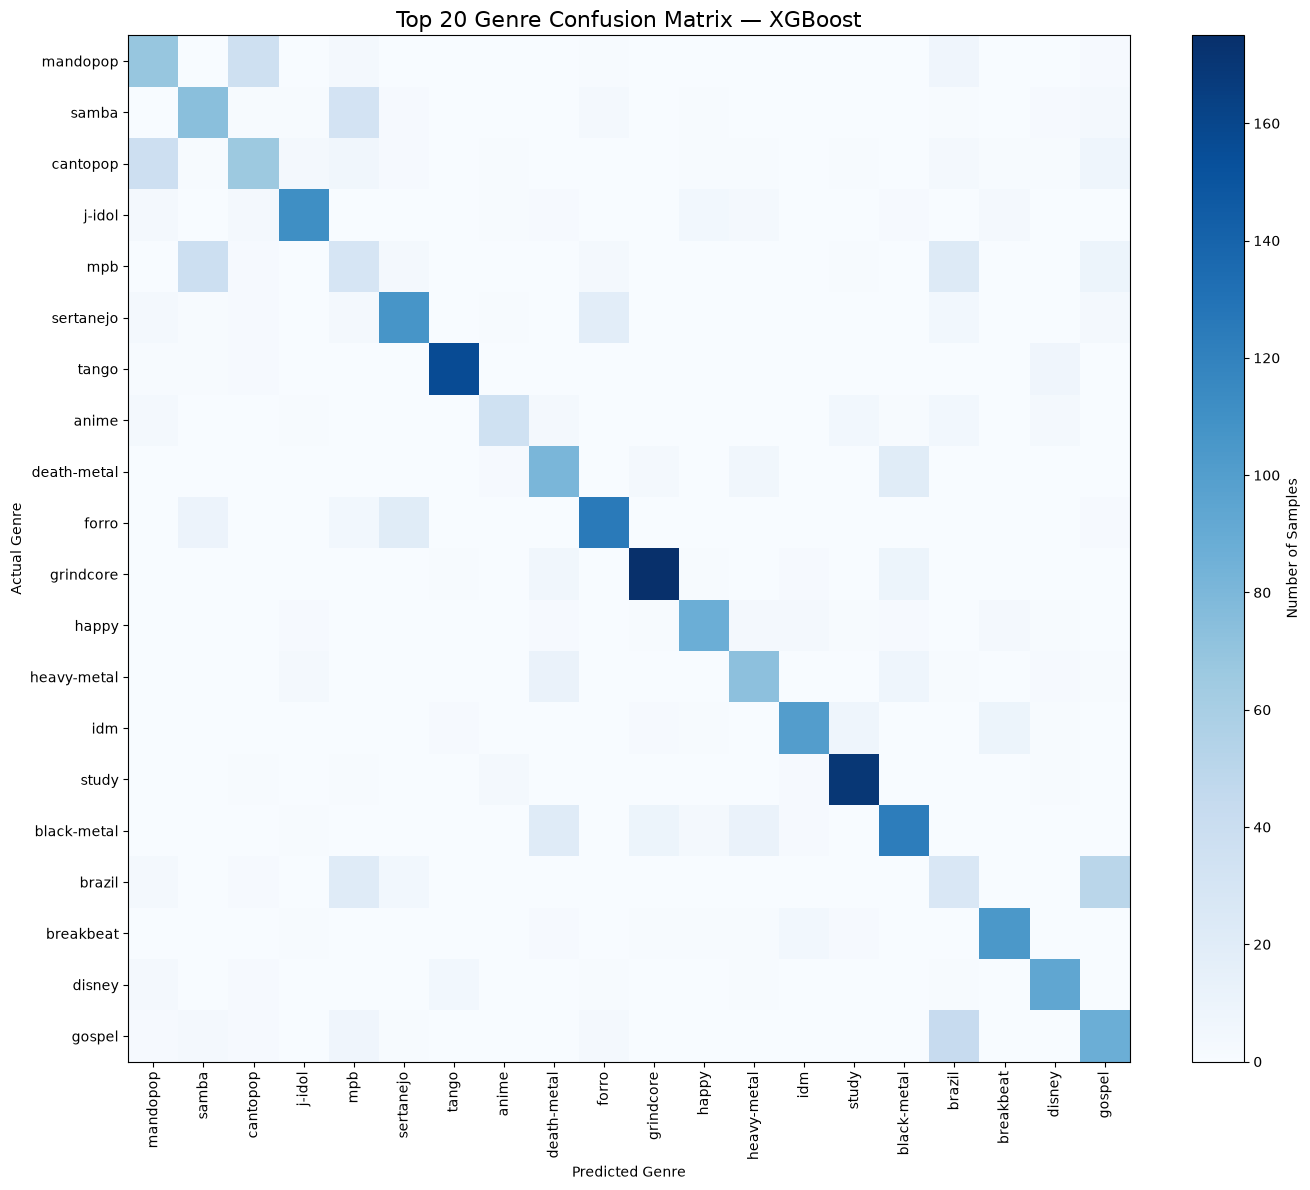

In [88]:
# Get top 20 genres
top_20_genres = (
    df["track_genre"]
    .value_counts()
    .head(20)
    .index
)

# Convert genre names to encoded labels
top_20_labels = label_encoder.transform(
    top_20_genres
)

# Confusion matrix
cm_top20 = confusion_matrix(
    y_test,
    best_predictions,
    labels=top_20_labels
)

plt.figure(figsize=(14, 12))

plt.imshow(
    cm_top20,
    aspect="auto",
    cmap="Blues"
)

plt.colorbar(
    label="Number of Samples"
)

plt.title(
    f"Top 20 Genre Confusion Matrix — {best_model_name}",
    fontsize=16
)

plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")

plt.xticks(
    range(len(top_20_genres)),
    top_20_genres,
    rotation=90
)

plt.yticks(
    range(len(top_20_genres)),
    top_20_genres
)

plt.tight_layout()
plt.show()

## Feature Importance Analysis

Feature importance is used to understand which input features contribute most to the predictions made by a machine learning model.

In this project, XGBoost is used to calculate the importance of the Spotify audio features. The `feature_importances_` attribute provides an importance value for each feature based on its contribution to the decision trees in the trained XGBoost model.

The importance values are then combined with their corresponding feature names and sorted in descending order.

### Purpose

Feature importance analysis helps to:

- Identify the most influential Spotify audio features.
- Understand which features contribute more to genre classification.
- Determine which musical characteristics are useful for distinguishing genres.
- Improve the interpretability of the machine learning model.
- Provide useful insights for the final project analysis.

A higher feature importance value indicates that the feature was more useful to the XGBoost model when making its predictions.

The feature importance values are model-specific and do not necessarily mean that a feature has a causal relationship with the predicted genre.

### Features Analyzed

The analysis considers the following Spotify audio features:

- Popularity
- Duration
- Explicit
- Danceability
- Energy
- Key
- Loudness
- Mode
- Speechiness
- Acousticness
- Instrumentalness
- Liveness
- Valence
- Tempo
- Time Signature

In [89]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print(feature_importance)

             Feature  Importance
0         popularity    0.146596
2           explicit    0.120837
9       acousticness    0.076770
10  instrumentalness    0.075550
3       danceability    0.065849
1        duration_ms    0.059872
4             energy    0.058376
7               mode    0.057344
6           loudness    0.056803
12           valence    0.056603
13             tempo    0.052199
8        speechiness    0.051126
14    time_signature    0.048598
11          liveness    0.040151
5                key    0.033325


## XGBoost Feature Importance Visualization

The feature importance values obtained from the XGBoost model are visualized using a horizontal bar chart.

Each bar represents one Spotify audio feature, and the length of the bar represents its importance in the XGBoost model.

The features are displayed in descending order of importance by reversing the y-axis. This makes it easier to identify the most influential features at the top of the graph.

### Purpose

This visualization helps to:

- Identify the most important features used by XGBoost.
- Compare the contribution of different Spotify audio features.
- Improve the interpretability of the classification model.
- Understand which musical characteristics are useful for genre prediction.

A feature with a higher importance value contributed more to the tree-based model's decision-making process than a feature with a lower importance value.

Feature importance represents model-based contribution and should not be interpreted as a direct causal relationship between an audio feature and music genre.

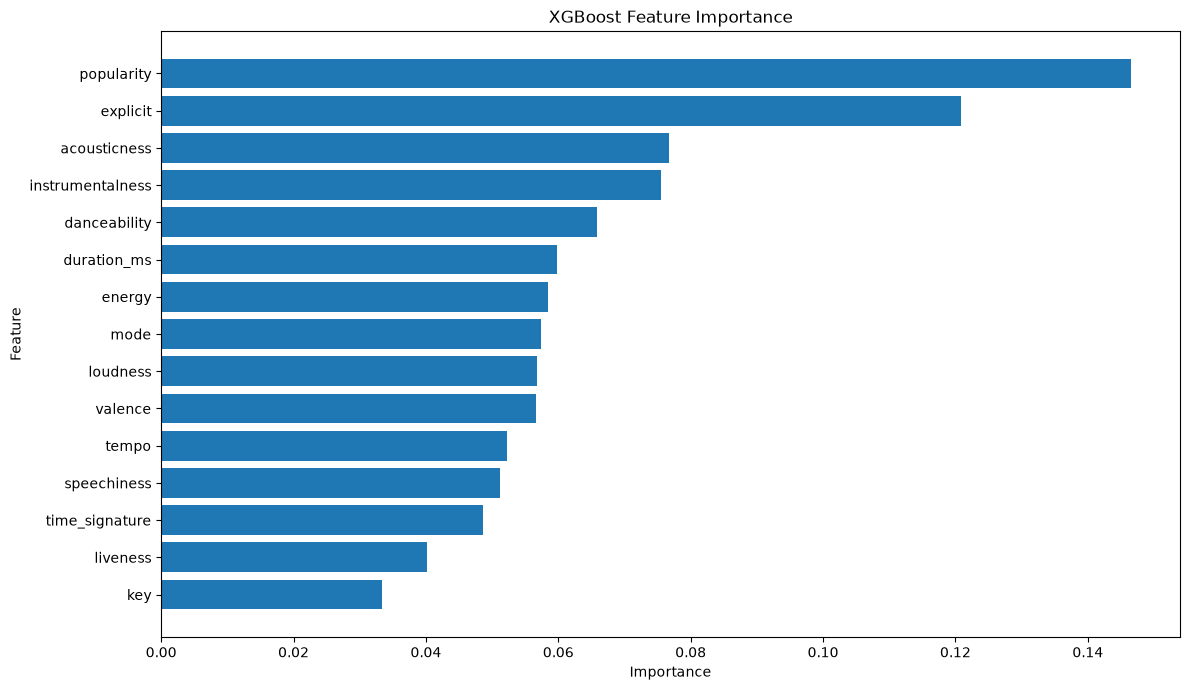

In [90]:
plt.figure(figsize=(12, 7))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title(
    "XGBoost Feature Importance"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## Overall Performance Comparison of Classification Models

After training and evaluating the five machine learning models, their performance is compared using four evaluation metrics: Accuracy, Precision, Recall, and Macro F1-Score.

A grouped bar chart is used to visualize the performance of all models in a single graph.

### Evaluation Metrics

- **Accuracy:** Measures the overall proportion of correctly classified tracks.
- **Precision:** Measures how many tracks predicted as a particular genre are actually from that genre.
- **Recall:** Measures how many tracks belonging to a particular genre are correctly identified.
- **Macro F1-Score:** Calculates the F1-Score for each genre and gives equal importance to every genre by taking their average.

### Purpose

The comparison helps determine the strengths and weaknesses of the five classification models:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Linear SVM
4. Random Forest
5. XGBoost

The model with consistently higher evaluation scores, particularly the highest Macro F1-Score, can be considered the most effective model for the Spotify music genre classification task.

This visualization provides a clear comparison of the models and supports the selection of the final best-performing model.

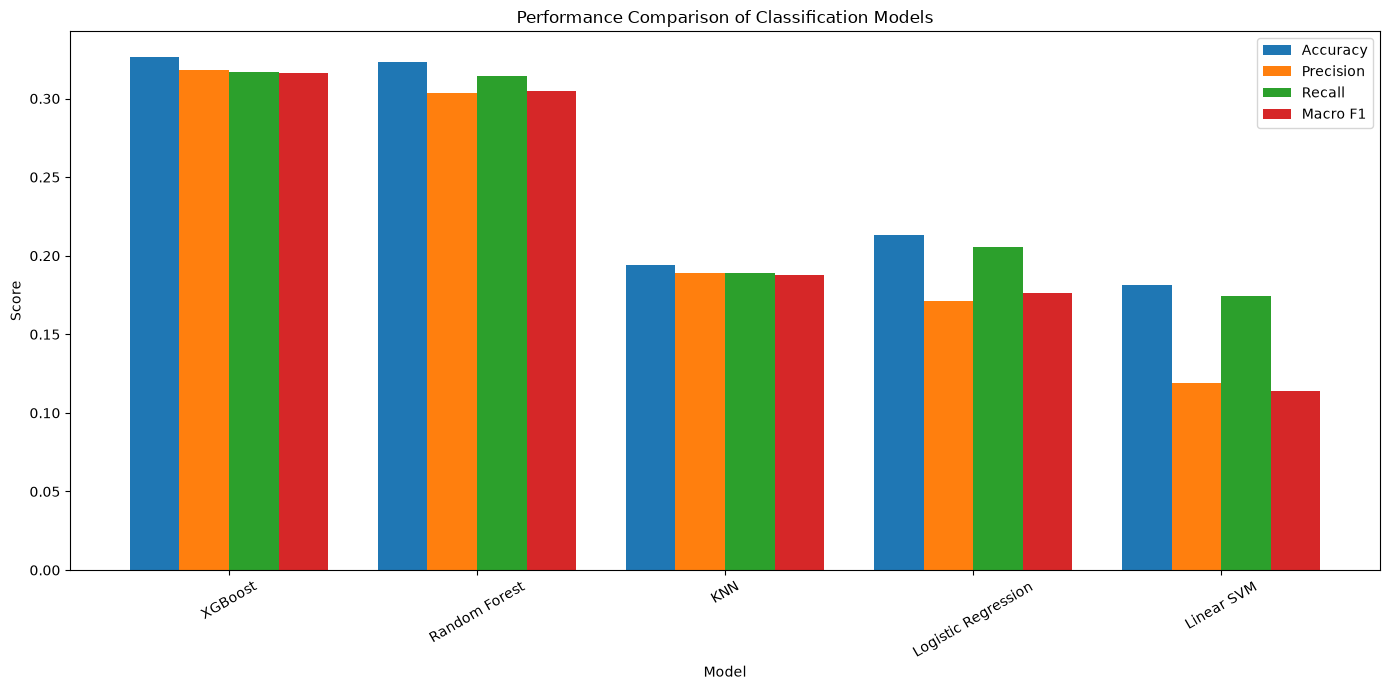

In [91]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Macro F1"
]

x = np.arange(len(results["Model"]))

width = 0.2

plt.figure(figsize=(14, 7))

for i, metric in enumerate(metrics):

    plt.bar(
        x + i * width,
        results[metric],
        width,
        label=metric
    )

plt.xticks(
    x + width * 1.5,
    results["Model"],
    rotation=30
)

plt.xlabel("Model")
plt.ylabel("Score")

plt.title(
    "Performance Comparison of Classification Models"
)

plt.legend()

plt.tight_layout()
plt.show()

## Final Model Comparison

The final performance of all five machine learning models is summarized in a comparison table.

The table contains the following evaluation metrics:

- **Accuracy:** Measures the overall percentage of correctly classified tracks.
- **Precision:** Measures the correctness of the genre predictions.
- **Recall:** Measures how effectively the model identifies the actual samples belonging to each genre.
- **Macro F1-Score:** Calculates the F1-Score independently for each genre and gives equal importance to every genre.

The models compared are:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Linear Support Vector Machine (SVM)
4. Random Forest
5. XGBoost

The results are displayed to four decimal places to make the comparison precise and easy to interpret.

The models were ranked primarily using the **Macro F1-Score**. The model with the highest Macro F1-Score is considered the best-performing model for the Spotify music genre classification task.

This final comparison provides a consolidated view of the performance of all the implemented machine learning models.

In [92]:
print("FINAL MODEL COMPARISON")
print("=" * 70)

display(
    results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro F1": "{:.4f}"
    })
)

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,Macro F1
0,XGBoost,0.3264,0.3181,0.3172,0.3165
1,Random Forest,0.3235,0.3038,0.3141,0.3048
2,KNN,0.1944,0.1893,0.1892,0.1878
3,Logistic Regression,0.2134,0.1709,0.2057,0.1761
4,Linear SVM,0.1816,0.1188,0.1741,0.1138


## Saving the Best Model for Future Prediction

After selecting the best-performing model, the trained model and the preprocessing objects are saved using the `joblib` library.

Three important objects are saved:

1. **Best Machine Learning Model**
   - Contains the trained classification model.
   - It is used to predict the genre of new music tracks.

2. **StandardScaler**
   - Stores the scaling parameters learned from the training data.
   - It is required to transform new input features in exactly the same way as the training data.

3. **LabelEncoder**
   - Stores the relationship between numerical encoded labels and the original genre names.
   - It is required to convert the model's numerical prediction back into the actual Spotify genre name.

### Why Save These Objects?

Saving these objects avoids retraining the model every time a new prediction is required.

For a new song, the prediction process will be:

New Spotify Audio Features
        ↓
Load Saved Scaler
        ↓
Scale the Features
        ↓
Load Saved Best Model
        ↓
Predict Encoded Genre
        ↓
Load Saved Label Encoder
        ↓
Convert Encoded Label to Genre Name
        ↓
Final Predicted Genre

The files are saved in `.pkl` format, which can later be loaded using `joblib.load()`.

This step prepares the machine learning model for practical use and future deployment.

In [93]:
import joblib

model_dictionary = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Linear SVM": svm_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

best_model = model_dictionary[best_model_name]

joblib.dump(
    best_model,
    "best_spotify_genre_model.pkl"
)

joblib.dump(
    scaler,
    "spotify_genre_scaler.pkl"
)

joblib.dump(
    label_encoder,
    "spotify_genre_label_encoder.pkl"
)

print("Best model saved successfully!")
print("Model:", best_model_name)

Best model saved successfully!
Model: XGBoost


## Conclusion

This project developed a machine learning-based system for Spotify music genre classification using audio features such as danceability, energy, loudness, acousticness, instrumentalness, valence, tempo, and popularity.

Five classification algorithms were implemented and compared: Logistic Regression, K-Nearest Neighbors, Linear SVM, Random Forest, and XGBoost. The models were evaluated using Accuracy, Precision, Recall, and Macro F1-Score.

Confusion matrix analysis was performed to examine correct and incorrect genre predictions, while TP, TN, FP, and FN analysis provided additional insight into classification performance using a One-vs-Rest approach.

The best-performing model was selected based on Macro F1-Score and further analyzed using a detailed classification report and feature importance analysis.

The developed model can be used to predict the genre of previously unseen tracks based on their Spotify audio characteristics.